<a href="https://colab.research.google.com/github/infinityrohit07/tensorflow-learning/blob/main/notebooks/16_phase1_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## What is Classification?

Classification is a supervised machine learning task where a model learns to assign an input to a category or class.

Unlike regression, which predicts continuous numerical values, classification predicts which category an input belongs to.

### Real-World Examples

| Problem | Input | Output |
|---|---|---|
| Spam Detection | Email content | Spam / Not Spam |
| Tumor Classification | Tumor measurements | Benign / Malignant |
| Flower Classification | Flower measurements | Setosa / Versicolor / Virginica |
| Customer Purchase Prediction | Customer information | Buy / Not Buy |

<br>

### Regression vs Classification

| Regression | Classification |
|---|---|
| Predicts numerical values | Predicts categories |
| House price = ₹50 lakh | Email = Spam |
| Temperature = 32.5°C | Tumor = Benign |
| Output is continuous | Output represents a class |

<br>

### How Does a Classification Model Learn?

The general training process is similar to regression:

1. Provide the model with training data.
2. The model learns patterns from features and labels.
3. The model generates predictions.
4. Calculate prediction error using a loss function.
5. The optimizer updates the model's parameters.
6. Repeat the process until the model learns useful patterns.

## Types of Classification

There are three important types of classification:

1. Binary Classification
2. Multiclass Classification
3. Multilabel Classification

### 1. Binary Classification

Binary classification is a type of classification where a model predicts one of exactly two possible classes.

<br>

Examples:

| Problem | Class 0 | Class 1 |
|---|---|---|
| Email Detection | Not Spam | Spam |
| Customer Behaviour | Not Buy | Buy |
| Medical Diagnosis | Benign | Malignant |
| Loan Prediction | Not Approved | Approved |
| Fraud Detection | Not Fraud | Fraud |

Binary classes are commonly represented using numerical values:

- `0` represents the first class.
- `1` represents the second class.

<br>

**Example: Customer Purchase Prediction**

| Customer | Age | Income | Purchased (y) |
|---|---:|---:|---:|
| A | 22 | 20000 | 0 |
| B | 35 | 50000 | 1 |
| C | 28 | 30000 | 0 |
| D | 42 | 70000 | 1 |
| E | 31 | 45000 | 1 |

The model learns patterns from customer information to predict whether a customer will purchase a product.

<br>

**Important:** Binary classification does not mean the model can only receive two input features. It means the model predicts one of exactly two possible classes.

For example, a model can use 10 input features and still be a binary classification model.

### 2. Multiclass Classification

Multiclass classification is a type of classification where a model predicts one class from three or more possible classes.

<br>

**Example: Flower Classification**

A model identifies a flower as one of the following:

| Flower | Class Label |
|---|---:|
| Setosa | 0 |
| Versicolor | 1 |
| Virginica | 2 |

<br>

Other examples:

- Handwritten digit recognition (0–9).
- Animal classification (Cat, Dog, Horse).
- News classification (Sports, Politics, Technology).

<br>

**Important:** In multiclass classification, the model predicts one class from multiple possible classes.

### 3. Multilabel Classification

Multilabel classification is a type of classification where a model can assign multiple labels to the same input simultaneously.

<br>

**Example: Image Classification**

An image contains a dog playing with a ball in a park.

The model may identify all three labels:

- Dog
- Ball
- Outdoor

Unlike multiclass classification, the model does not have to choose just one class.

<br>

#### **Representing Multilabel Targets**

Suppose we have three possible labels:

1. Dog
2. Ball
3. Outdoor

We can represent them using a binary vector:

| Image | Dog | Ball | Outdoor |
|---|---:|---:|---:|
| Image A | 1 | 1 | 1 |
| Image B | 1 | 0 | 1 |
| Image C | 0 | 1 | 0 |

Here:
- `1` means the label is present.
- `0` means the label is absent.

For Image A:

$$
y = [1, 1, 1]
$$

The image contains all three labels.

### Comparison of Classification Types

| Type | Possible Output | Prediction |
|---|---|---|
| Binary | Exactly 2 classes | One class |
| Multiclass | 3 or more classes | One class |
| Multilabel | Multiple possible labels | One or more labels |

<br>

Examples:

- Binary: Spam or Not Spam.
- Multiclass: Cat or Dog or Horse.
- Multilabel: Dog + Ball + Outdoor.

## Features (X) and Labels (y) in Classification

In supervised machine learning, a model learns from input features (`X`) and their corresponding labels (`y`).

- **Features (X):** Input information provided to the model.
- **Labels (y):** Actual target values that the model needs to predict.

In classification, labels represent categories or classes rather than continuous numerical values.

### **Example: Spam Detection**

Imagine we want to build a machine learning model that identifies whether an email is spam.

Our dataset contains the following information:

| Email | Contains links | Contains suspicious words | Spam (y) |
|---|---:|---:|---:|
| A | 1 | 1 | 1 |
| B | 0 | 0 | 0 |
| C | 1 | 0 | 0 |
| D | 1 | 1 | 1 |
| E | 0 | 1 | 0 |

Here:

- **X (Features):** Contains links and contains suspicious words.
- **y (Label):** Whether the email is spam.
- `0` represents Not Spam.
- `1` represents Spam.

The model learns patterns from the input features to predict whether an email belongs to the Spam or Not Spam category.

### Representing the Dataset Using TensorFlow

In [1]:
import tensorflow as tf

# Features (X)
X = tf.constant([
    [1, 1],
    [0, 0],
    [1, 0],
    [1, 1],
    [0, 1]
], dtype=tf.float32)

# Labels (y)
y = tf.constant([1, 0, 0, 1, 0], dtype=tf.float32)

### Understanding the Shapes

In [2]:
print(X.shape)
print(y.shape)

(5, 2)
(5,)


Explanation:

- `5` represents the number of samples.
- `2` represents the number of features per sample.
- `y` contains one label for each of the five samples.

Therefore:

- X has 5 samples and 2 features.
- y has 5 corresponding labels.

## Class Labels

In classification, the model learns to predict categories called **classes**.

We need to represent these classes in a format that a neural network can work with.

There are different ways to represent class labels.

### 1. Integer Labels

Integer encoding assigns a unique integer to each class.

Example: Classifying Iris flowers.

| Flower | Integer Label |
|---|---:|
| Setosa | 0 |
| Versicolor | 1 |
| Virginica | 2 |

Using TensorFlow:

```python
import tensorflow as tf

y = tf.constant([0, 1, 2, 0, 1, 2])

print(y)
```

**Important:** These numbers are identifiers, not meaningful numerical quantities. Class 2 is not greater than class 1 in any meaningful sense.

### 2. Categorical Labels

Categorical labels represent classes using their actual names.

Example:

```python
y = ["Setosa", "Versicolor", "Virginica"]
```

Although these labels are easier for humans to understand, neural networks generally require numerical representations.

### 3. One-Hot Encoding

One-hot encoding represents each class using a binary vector.

For three classes:

| Class | One-Hot Representation |
|---|---|
| Setosa (0) | `[1, 0, 0]` |
| Versicolor (1) | `[0, 1, 0]` |
| Virginica (2) | `[0, 0, 1]` |

Only the position corresponding to the class contains `1`. All other positions contain `0`.

### TensorFlow Implementation

In [3]:
# Integer labels
labels = tf.constant([0, 1, 2])

# Converting integer labels into one-hot encoding
one_hot_labels = tf.one_hot(labels, depth=3)

print(one_hot_labels)

tf.Tensor(
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]], shape=(3, 3), dtype=float32)


**Understanding depth**

`depth=3` means there are three possible classes, so every one-hot vector contains three positions.

**Remember:** Indexing starts at zero.

For example, class `2` with `depth=4` becomes:

```python
[0, 0, 1, 0]
```

## Classification Output Layer

The output layer is the final layer of a neural network.

Its job is to produce the model's output based on the input features processed by the network.

In classification, the output represents the model's prediction about which class or classes an input belongs to.

The output layer depends on the type of classification problem.

There are three important types:

1. Binary classification
2. Multiclass classification
3. Multilabel classification

### 1. Binary Classification Output Layer

Binary classification involves exactly two possible classes.

Example: Spam detection.

| Class | Label |
|---|---:|
| Not Spam | 0 |
| Spam | 1 |

<br>

A common approach is to use **one output neuron** with sigmoid activation.

Example:

```python
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, activation="sigmoid")
])
```

Here:

- `Dense(1)` creates one output neuron.
- `activation="sigmoid"` converts the neuron's raw output into a value between 0 and 1.

<br>

#### **How One Output Neuron Represents Two Classes**

The sigmoid output represents the predicted probability of the **positive class (class 1)**.

For example:

| Sigmoid Output | Probability of Spam | Probability of Not Spam |
|---:|---:|---:|
| 0.90 | 90% | 10% |
| 0.70 | 70% | 30% |
| 0.30 | 30% | 70% |
| 0.10 | 10% | 90% |

The probability of the negative class can be calculated using:

$$
P(\text{Class 0}) = 1 - P(\text{Class 1})
$$

For example, if the model outputs `0.90`:

- Spam = 90%
- Not Spam = 10%

Therefore, one output neuron can represent both possible classes.

### 2. Multiclass Classification Output Layer

Multiclass classification involves choosing **exactly one class from three or more possible classes**.

Example: Classifying an animal image.

Possible classes:

| Animal | Label |
|---|---:|
| Cat | 0 |
| Dog | 1 |
| Horse | 2 |

<br>

A common approach is to use **one output neuron for each class**, with softmax activation.

Example:

```python
model = tf.keras.Sequential([
    tf.keras.layers.Dense(3, activation="softmax")
])
```

Here:

- `Dense(3)` creates three output neurons because we have three classes.
- `activation="softmax"` converts the raw outputs into probabilities.

<br>

#### Understanding the Output

Suppose the model produces:

| Class | Softmax Probability |
|---|---:|
| Cat | 0.70 |
| Dog | 0.20 |
| Horse | 0.10 |

The probabilities add up to 1 (100%).

$$
0.70 + 0.20 + 0.10 = 1
$$

The model predicts Cat because it has the highest probability.

<br>

**Important characteristics:**

- One output neuron per class.
- Softmax activation is commonly used.
- All class probabilities add up to 1.
- The model predicts one class.

## 3. Multilabel Classification Output Layer

Multilabel classification allows a model to predict **multiple labels for a single input simultaneously**.

Example: An image may contain:

- Dog
- Person
- Car

Unlike multiclass classification, multiple labels can be correct at the same time.

<br>

A common approach is to use **one output neuron for each possible label**, with sigmoid activation on each neuron independently.

Example:

```python
model = tf.keras.Sequential([
    tf.keras.layers.Dense(3, activation="sigmoid")
])
```

Here:

- `Dense(3)` creates three output neurons because we have three possible labels.
- `activation="sigmoid"` independently converts each neuron's output into a probability.

<br>

#### Understanding the Output

Suppose the model produces:

| Label | Sigmoid Probability |
|---|---:|
| Dog | 0.95 |
| Person | 0.85 |
| Car | 0.10 |

Using a threshold of `0.5`, the predictions would be:

| Label | Probability | Predicted Label |
|---|---:|---|
| Dog | 0.95 | 1 |
| Person | 0.85 | 1 |
| Car | 0.10 | 0 |

The final prediction is:

```python
[1, 1, 0]
```

This means the image contains a Dog and a Person, but not a Car according to the model's predictions.

<br>

**Important characteristics:**

- One output neuron per possible label.
- Sigmoid activation is commonly used.
- Each label gets an independent probability.
- Multiple labels can be predicted simultaneously.
- The probabilities do not have to add up to 1.

## Sigmoid Activation

Sigmoid is an activation function commonly used in **binary classification**.

It transforms any real-valued input into a value between 0 and 1.

This makes its output suitable for representing the predicted probability of the positive class.

<br>

### Sigmoid Formula

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Where:

- $(z)$ = Raw input to the sigmoid function (logit).
- $(e)$ = Euler's mathematical constant.
- $\sigma(z)$ = Sigmoid output.

<br>

### **How Sigmoid Transforms Values**

| Raw Input (z) | Sigmoid Output |
|---:|---:|
| -10 | Approximately 0.000 |
| -2 | 0.119 |
| 0 | 0.500 |
| 2 | 0.881 |
| 10 | Approximately 1.000 |

Observations:

- Large negative inputs produce outputs approaching 0.
- An input of 0 produces exactly 0.5.
- Large positive inputs produce outputs approaching 1.

**Important:** Sigmoid outputs approach 0 and 1 but never actually reach these values for finite inputs.

<br>

### Understanding Sigmoid Output

In binary classification, sigmoid output represents the predicted probability of the positive class (class 1).

Example:

If sigmoid outputs `0.95`:

- Positive class (1) = 95%
- Negative class (0) = 5%

If sigmoid outputs `0.20`:

- Positive class (1) = 20%
- Negative class (0) = 80%

The probability of the negative class is:

$$
P(\text{Class 0}) = 1 - P(\text{Class 1})
$$

### Visualizing Sigmoid Using Matplotlib

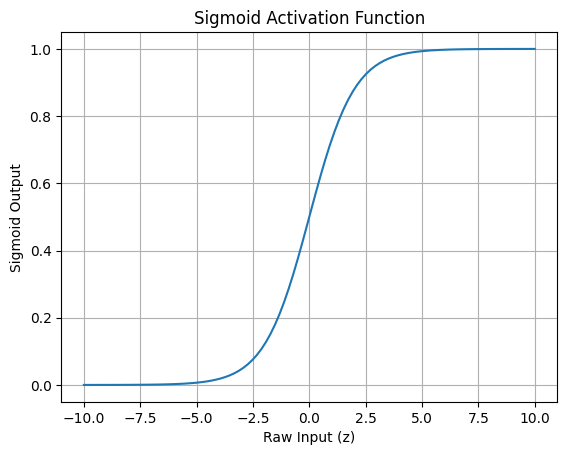

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Generating values from -10 to 10
z = np.linspace(-10, 10, 100)

# Applying sigmoid formula
sigmoid = 1 / (1 + np.exp(-z))

# Plot the curve
plt.plot(z, sigmoid)

plt.xlabel("Raw Input (z)")
plt.ylabel("Sigmoid Output")
plt.title("Sigmoid Activation Function")

plt.grid()
plt.show()

The sigmoid graph has an S-shaped curve.

Important observations:

- Negative inputs produce outputs below 0.5.
- An input of zero produces an output of 0.5.
- Positive inputs produce outputs above 0.5.

### Probability vs Accuracy

These two concepts are different.

**Probability:** Represents how likely the model thinks an input belongs to a particular class.

**Accuracy:** Measures how often the model's predictions are correct across a dataset.

For example, a sigmoid output of `0.95` means a 95% predicted probability for the positive class. It does not mean the model has 95% accuracy.

## Softmax Activation

Softmax is an activation function commonly used in multiclass classification.

It converts multiple raw numerical outputs (logits) into probabilities.

These probabilities represent how likely the model thinks an input belongs to each possible class.

<br>

### **Why Do We Need Softmax?**

Suppose we are building an image classification model that identifies animals.

Our possible classes are:

| Animal | Label |
|---|---:|
| Cat | 0 |
| Dog | 1 |
| Horse | 2 |

The model processes an image and produces three raw numerical outputs.

Example:

```python
logits = [2.5, 1.2, 0.3]
```

These values are not probabilities.

We want to convert them into probabilities so we can compare how likely each class is.

That's where Softmax comes in.

<br>

### **Softmax Formula**

$$
P(y_i)=\frac{e^{z_i}}{\sum_{j=1}^{n}e^{z_j}}
$$

Where:

- $(z_i)$ = Raw output (logit) for a particular class.
- $(e)$ = Euler's mathematical constant.
- $(n)$ = Total number of classes.
- $P(y_i)$ = Probability assigned to that class.

Softmax applies the exponential function to each logit and divides it by the sum of all exponentials.

<br>

### **Example of Softmax**

Suppose our model produces these raw outputs:

| Class | Raw Output |
|---|---:|
| Cat | 2.5 |
| Dog | 1.2 |
| Horse | 0.3 |

After applying Softmax, we get approximately:

| Class | Probability |
|---|---:|
| Cat | 0.709 |
| Dog | 0.194 |
| Horse | 0.097 |

The probabilities add up to approximately 1.

$$
0.709 + 0.194 + 0.097 = 1
$$

The model predicts Cat because it has the highest probability.

<br>

### **Important Properties of Softmax**

1. Converts multiple logits into probabilities.
2. Every probability is between 0 and 1.
3. All probabilities add up to 1.
4. The class with the highest probability is selected as the prediction.
5. It is commonly used for multiclass classification.

**Important:** Softmax is commonly used when the model must choose exactly one class from multiple possible classes.


### Implementing Softmax Using TensorFlow


In [5]:
import tensorflow as tf

# Raw outputs from a model for three classes
logits = tf.constant([2.5, 1.2, 0.3])

# Apply softmax
probabilities = tf.nn.softmax(logits)

print("Logits:", logits.numpy())
print("Probabilities:", probabilities.numpy())

# Check the sum of probabilities
print("Total:", tf.reduce_sum(probabilities).numpy())

Logits: [2.5 1.2 0.3]
Probabilities: [0.72289073 0.19701073 0.08009857]
Total: 1.0


### Finding the Predicted Class Using `tf.argmax()`



In [6]:
# We can use tf.argmax() to find the index of the class with the highest probability.

predicted_class = tf.argmax(probabilities)

print(predicted_class.numpy())

0


This means the model predicts Class 0 (Cat).

## Logits and Probabilities

### **1. What are Logits?**

Logits are the raw numerical outputs produced by a model before applying an activation function such as Sigmoid or Softmax.

Remember the neuron calculation:

$$
z = wx+b
$$

Where:

- $(w)$ = Weight.
- $(x)$ = Input.
- $(b)$ = Bias.
- $(z)$ = Raw output (logit).

For example:

```python
logits = [-2.0, 1.5, 3.0]
```

These values are not probabilities.

Logits can be:

- Negative.
- Positive.
- Zero.
- Greater than 1.

There is no requirement for logits to add up to 1.

<br>

### 2. **What are Probabilities?**

Probabilities represent how likely the model thinks an input belongs to a particular class.

We obtain them by applying an activation function to logits.

For binary classification, we commonly use Sigmoid.

For multiclass classification, we commonly use Softmax.

<br>

**Example: Multiclass Classification**

Suppose a model produces these logits:

```python
logits = [-2.0, 1.5, 3.0]
```

After applying Softmax, we get approximately:

| Class | Logit | Probability |
|---|---:|---:|
| Class 0 | -2.0 | 0.005 |
| Class 1 | 1.5 | 0.179 |
| Class 2 | 3.0 | 0.816 |

The probabilities add up to approximately 1.

The model predicts Class 2 because it has the highest probability.

<br>

### 3. **Logits vs Probabilities**

| Logits | Probabilities |
|---|---|
| Raw model outputs | Outputs after activation |
| Can be negative or positive | Between 0 and 1 |
| Don't need to sum to 1 | Softmax probabilities sum to 1 |
| Not directly interpreted as probabilities | Can be interpreted as probabilities |

<br>

**Important:** Sigmoid probabilities for multilabel classification are independent and do not have to add up to 1.

### Understanding This in TensorFlow

In [7]:
import tensorflow as tf

# Raw model outputs (logits)
logits = tf.constant([-2.0, 1.5, 3.0])

# Convert logits into probabilities
probabilities = tf.nn.softmax(logits)

print("Logits:", logits.numpy())
print("Probabilities:", probabilities.numpy())

Logits: [-2.   1.5  3. ]
Probabilities: [0.00547859 0.18142608 0.8130953 ]


Here:

- `logits` contains raw numerical outputs.
- `tf.nn.softmax()` converts them into probabilities.

### What is from_logits in TensorFlow?

When building classification models, TensorFlow's loss functions sometimes expect logits rather than probabilities.

For example:

```python
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)
```

`from_logits=True` tells the loss function that the model produces raw logits instead of probabilities.

The loss function handles the required conversion internally in a numerically stable way.

**Important:** If we use `from_logits=True`, we should provide raw logits from the output layer rather than applying Softmax beforehand.

For example:

```python
model = tf.keras.Sequential([
    tf.keras.layers.Dense(3)
])
```

Here, the output layer does not apply Softmax, so it produces logits.

We'll explore this later.

## Classification Threshold

A classification threshold is a cutoff value used to convert predicted probabilities into class labels (0 or 1).

The commonly used default threshold is `0.5`.

- Probability >= 0.5 → Class 1.
- Probability < 0.5 → Class 0.

<br>

### Changing the Threshold

We can change the threshold depending on the problem.

| Probability | Threshold 0.7 | Threshold 0.3 |
|---:|---:|---:|
| 0.20 | 0 | 0 |
| 0.45 | 0 | 1 |
| 0.60 | 0 | 1 |
| 0.80 | 1 | 1 |
| 0.95 | 1 | 1 |

**Remember:**
- Lower threshold → More positive predictions.
- Higher threshold → Fewer positive predictions.

### Implementing Threshold in TensorFlow

In [8]:
import tensorflow as tf

# Predicted probabilities for classes A, B, C, D, E
predictions = tf.constant([0.20, 0.45, 0.60, 0.80, 0.95])

# Setting threshold
threshold = 0.70

# Converting probabilities into class labels
predicted_classes = tf.cast(
    predictions >= threshold,
    dtype=tf.int32
)

print(predicted_classes.numpy())

[0 0 0 1 1]


the output tells us our output has class D and class E.

### Why Do We Change Thresholds?

Different problems require different thresholds.

For example, in disease detection, we might lower the threshold to identify more potentially positive cases.

This usually increases recall but can also increase false positives.